# 21. Comparación estadística de modelos

Con 140 combinaciones en la validación anidada, 26 + 28 en la evaluación definitiva, más el modelo propuesto y
las líneas base, hay cientos de pares posibles. Comparar todos con pruebas sueltas a α = 0,05 produciría
decenas de falsos positivos solo por azar. Se sigue la **secuencia jerárquica** de la sección 6 del enunciado:

| Tarea | Etapa 1 (global) | Etapa 2 (post-hoc / filtrado) | Etapa 3 (dirigidas) | Tamaño del efecto |
|---|---|---|---|---|
| Clasificación | Friedman (+ Iman-Davenport) | Nemenyi + diagrama de Diferencia Crítica | DeLong entre los mejores, con Holm y bootstrap | δ de Cliff |
| Regresión | Model Confidence Set (MCS) | Giacomini-White y Clark-West entre finalistas | Diebold-Mariano HLN con bootstrap estacionario, Holm | d de Cohen |

Además se aplica el **SPA de Hansen** con el Reality Check de White para controlar el *data snooping* (21.7). La sección 21.8 verifica la independencia de los residuos, supuesto que condiciona cómo
deben hacerse estas pruebas.

**Evaluación.** Todas las pruebas sobre pronósticos usan la **evaluación definitiva en origen móvil
2021–2026** (cap. 13.11): 69 meses, modelos reentrenados cada año. La única excepción es la etapa (a) de
Friedman, que usa los bloques del bucle externo de la validación anidada.

**Unidad de análisis y dependencia espacial y temporal.** Cada mes hay pronósticos para unas 160 celdas, y esas
celdas **no son observaciones independientes**: las vecinas comparten sismos (réplicas, enjambres) y un mes
activo eleva el error de muchas celdas a la vez. Por eso ninguna prueba de regresión trata las 11 754
celda-mes como observaciones independientes. La unidad de análisis es el **mes**: para cada modelo se calcula
la pérdida media de todas las celdas del mes (L_m,t), y las pruebas comparan series de 69 valores mensuales
pareados. Así:

- **la dependencia espacial dentro de un mes** queda absorbida en el promedio mensual (no se cuentan celdas
  vecinas como evidencia separada);
- **la dependencia temporal entre meses** se trata con varianza de Newey-West (DM, GW, CW) y con bootstrap
  estacionario de bloques de meses (IC, MCS, SPA);
- **se verifica empíricamente** en 21.8: la serie mensual de residuos no muestra autocorrelación (Escanciano-
  Lobato, Breusch-Godfrey) y el I de Moran de los residuos de cada mes es cercano a cero.

En clasificación se usa el AUC de cada mes con el mismo criterio. DeLong usa las filas porque así está definido,
y se acompaña de un IC por bootstrap de meses.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Predicciones del origen móvil y resultados de la validación anidada
from sklearn.metrics import roc_auc_score
from src import resultados_e2 as r2, estadistica as est
ev_, X, info, tr, gp, te = datos.panel_completo()
CLF = r2.cargar("clf")                                   # validación anidada (Friedman a)
C, O, Fi = r2.origen_movil_clf(), r2.origen_movil(), r2.filas_origen_movil()
yb, tmt = C["y"], C["tm"]                                # clasificación, origen móvil
yr, tmr = O["y"], O["tm"]                                # regresión, origen móvil
meses_te = np.unique(tmt)
CAMP_C, CAMP_R = r2.campeones_om("clf"), r2.campeones_om("reg")
persist, estac = info["C"][Fi["cc"], Fi["tt"]], info["C"][Fi["cc"], Fi["tt"] - 11]
assert np.array_equal(info["C"][Fi["cc"], Fi["tt"] + 1], yr)

## Clasificación
### 21.1 Etapa 1: prueba de Friedman

H0: todos los modelos tienen el mismo rendimiento (rangos medios iguales). Se aplica en dos niveles:

- **(a) Las 112 combinaciones de clasificación sobre los 3 pliegues del bucle externo** de la validación
  anidada (lo que pide el enunciado). Con solo 3 bloques la prueba tiene poca potencia.
- **(b) El campeón de cada uno de los 7 modelos** (elegido con la validación anterior a 2016) **sobre los 69
  meses del origen móvil**, usando el AUC de cada mes. Más bloques → más potencia, y responde la pregunta
  práctica: ¿qué familia de modelos es mejor?

In [3]:
# Friedman: (a) 112 combinaciones × 3 bloques y (b) 7 campeones × 69 meses (AUC mensual)
Mext = np.array([r["externo"]["ROC_AUC"] for r in CLF]).T            # 3 × 112
fa = est.friedman(Mext, menor_mejor=False)
nombres7 = list(CAMP_C.modelo)
score7 = {m: C["combos"][e] for m, e in zip(CAMP_C.modelo, CAMP_C.etiqueta)}
auc_mes = np.array([[roc_auc_score(yb[tmt == m], score7[n][tmt == m]) for n in nombres7] for m in meses_te])
fb = est.friedman(auc_mes, menor_mejor=False)
FR = pd.DataFrame([{"nivel": f"(a) {len(CLF)} combinaciones × 3 bloques externos", "chi2_F": fa["chi2"], "gl": fa["gl"], "p": fa["p"], "F (Iman-Davenport)": fa["F_ID"], "p (ID)": fa["p_ID"]},
                   {"nivel": "(b) 7 campeones × 69 meses del origen móvil", "chi2_F": fb["chi2"], "gl": fb["gl"], "p": fb["p"], "F (Iman-Davenport)": fb["F_ID"], "p (ID)": fb["p_ID"]}])
FR["conclusión"] = np.where(FR.p < 0.05, "Se rechaza H0: hay diferencias", "No se rechaza H0")
eda.guardar_tabla(FR, "e2_stats_friedman.csv")
FR.round(5)

,nivel,chi2_F,gl,p,F (Iman-Davenport),p (ID),conclusión
0,(a) 112 combinaciones × 3 bloques externos,242.43616,111,0.0,5.35393,0.0,Se rechaza H0: hay diferencias
1,(b) 7 campeones × 69 meses del origen móvil,96.69565,6,0.0,20.72239,0.0,Se rechaza H0: hay diferencias


### 21.2 Etapa 2: Nemenyi y diagrama de Diferencia Crítica

Dos modelos son estadísticamente equivalentes si la diferencia de sus rangos medios es menor que la CD de
Nemenyi; el diagrama los une con una barra.

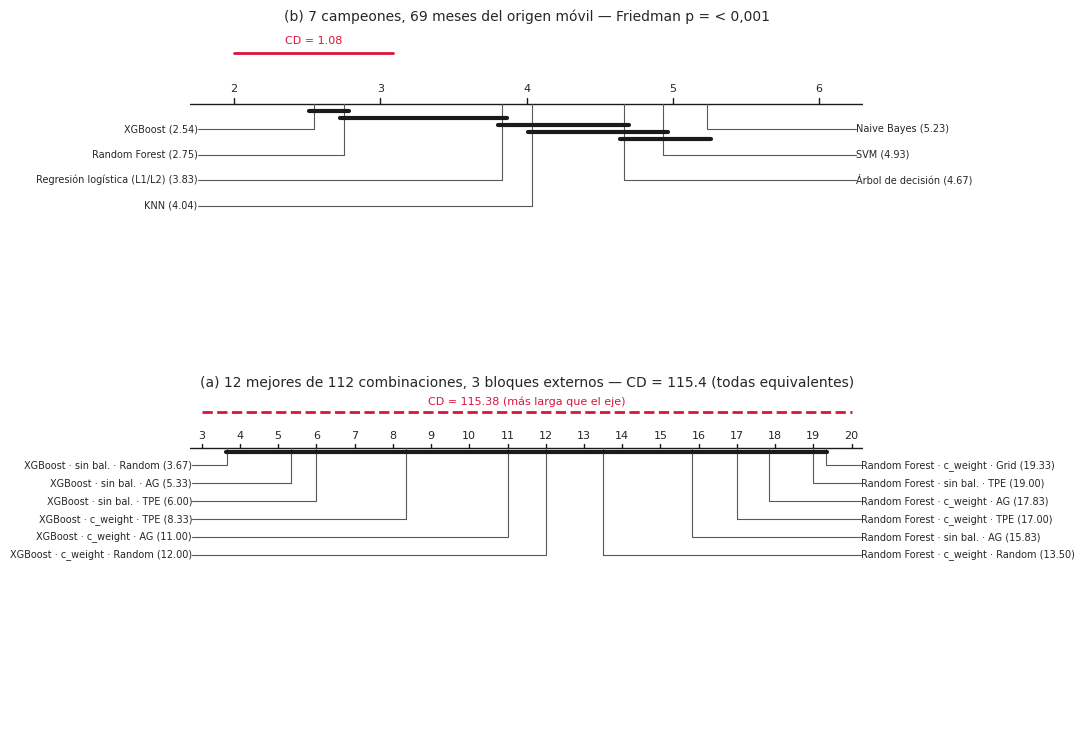

,XGBoost,Regresión logística (L1/L2),SVM,Random Forest,Árbol de decisión,KNN,Naive Bayes
XGBoost,1.0000,0.0082,0.0000,0.9976,0.0000,0.0010,0.0000
Regresión logística (L1/L2),0.0082,1.0000,0.0437,0.0518,0.2607,0.9980,0.0027
SVM,0.0000,0.0437,1.0000,0.0000,0.9908,0.1807,0.9843
Random Forest,0.9976,0.0518,0.0000,1.0000,0.0000,0.0088,0.0000
Árbol de decisión,0.0000,0.2607,0.9908,0.0000,1.0000,0.6065,0.7225
KNN,0.0010,0.9980,0.1807,0.0088,0.6065,1.0000,0.0197
Naive Bayes,0.0000,0.0027,0.9843,0.0000,0.7225,0.0197,1.0000


In [4]:
# Diagramas de diferencia crítica (Nemenyi)
cd7 = est.diferencia_critica(7, len(meses_te))
cdA = est.diferencia_critica(len(CLF), 3)
fig, axs = plt.subplots(2, 1, figsize=(11, 7.5))
grupos = est.grafico_cd(nombres7, fb["rangos"], cd7, axs[0], f"(b) 7 campeones, 69 meses del origen móvil — Friedman p = {p_fmt(fb['p'])}")
top12 = np.argsort(fa["rangos"])[:12]
est.grafico_cd([CLF[i]["etiqueta"] for i in top12], fa["rangos"][top12], cdA, axs[1],
               f"(a) 12 mejores de {len(CLF)} combinaciones, 3 bloques externos — CD = {cdA:.1f} (todas equivalentes)")
plt.tight_layout(); eda.guardar_figura(fig, "e2_stats_cd.png"); plt.show()
NP = est.nemenyi_pares(fb["rangos"], len(meses_te)); NP.index = NP.columns = nombres7
eda.guardar_tabla(NP.reset_index(), "e2_stats_nemenyi.csv")
NP.round(4)

In [5]:
# Lectura de Friedman y Nemenyi
orden = np.argsort(fb["rangos"])
md(f"- **(a)** Con 3 bloques y {len(CLF)} combinaciones, Friedman da p = {p_fmt(fa['p'])} pero la CD de Nemenyi es {cdA:.1f} rangos, mayor que "
   f"cualquier distancia posible entre las 12 primeras: con solo 3 pliegues **no hay potencia** para separar combinaciones, y por eso el "
   f"análisis útil es el (b).\n"
   f"- **(b)** Con 69 meses, Friedman {'rechaza' if fb['p'] < 0.05 else 'no rechaza'} H0 (p = {p_fmt(fb['p'])}). Orden por rango medio (1 = mejor): "
   + ", ".join(f"{nombres7[i]} ({fb['rangos'][i]:.2f})" for i in orden) +
   f". CD = {cd7:.2f}. Los modelos unidos por la misma barra no se distinguen; los que no comparten barra sí.")

- **(a)** Con 3 bloques y 112 combinaciones, Friedman da p = < 0,001 pero la CD de Nemenyi es 115.4 rangos, mayor que cualquier distancia posible entre las 12 primeras: con solo 3 pliegues **no hay potencia** para separar combinaciones, y por eso el análisis útil es el (b).
- **(b)** Con 69 meses, Friedman rechaza H0 (p = < 0,001). Orden por rango medio (1 = mejor): XGBoost (2.54), Random Forest (2.75), Regresión logística (L1/L2) (3.83), KNN (4.04), Árbol de decisión (4.67), SVM (4.93), Naive Bayes (5.23). CD = 1.08. Los modelos unidos por la misma barra no se distinguen; los que no comparten barra sí.

### 21.3 Etapa 3: DeLong entre los tres mejores modelos, con Holm

Subconjunto reducido y justificado: los **tres campeones con mejor AUC en la validación anterior a 2016**
(no por los meses evaluados). Se reportan la diferencia de AUC, el IC 95 % de DeLong, el IC 95 % por bootstrap
de meses, el p crudo y el p ajustado por Holm.

In [6]:
# DeLong entre los 3 mejores clasificadores con corrección de Holm
top3 = list(CAMP_C.modelo[:3])
filas = []
for i in range(3):
    for j in range(i + 1, 3):
        a, b = top3[i], top3[j]
        d = est.delong(yb, score7[a], score7[b])
        bs = est.bootstrap_auc_meses(yb, score7[a], score7[b], tmt, B=1000)
        ia, ib = nombres7.index(a), nombres7.index(b)
        filas.append({"modelo A": CAMP_C.etiqueta[ia], "modelo B": CAMP_C.etiqueta[ib], "AUC A": d["AUC_1"], "AUC B": d["AUC_2"], "diferencia": d["dif"],
                      "IC95 DeLong": f"[{d['IC_inf']:.4f}, {d['IC_sup']:.4f}]", "IC95 bootstrap meses": f"[{bs['IC_boot_inf']:.4f}, {bs['IC_boot_sup']:.4f}]",
                      "p crudo": d["p"], "δ Cliff (AUC mensual)": eda.delta_cliff(auc_mes[:, ia], auc_mes[:, ib])})
DL = pd.DataFrame(filas)
DL["p Holm"] = eda.holm(DL["p crudo"].values)
DL["magnitud δ"] = DL["δ Cliff (AUC mensual)"].map(est.magnitud_cliff)
eda.guardar_tabla(DL, "e2_stats_delong.csv")
DL.round(4)

,modelo A,modelo B,AUC A,AUC B,diferencia,IC95 DeLong,IC95 bootstrap meses,p crudo,δ Cliff (AUC mensual),p Holm,magnitud δ
0,XGBoost · c_weight,Regresión logística (L1/L2) · sin bal.,0.8096,0.8008,0.0087,"[0.0055, 0.0119]","[0.0050, 0.0125]",0.0,0.1128,0.0,despreciable
1,XGBoost · c_weight,SVM · ADASYN,0.8096,0.7936,0.0160,"[0.0124, 0.0196]","[0.0117, 0.0202]",0.0,0.2094,0.0,pequeño
2,Regresión logística (L1/L2) · sin bal.,SVM · ADASYN,0.8008,0.7936,0.0073,"[0.0041, 0.0104]","[0.0044, 0.0101]",0.0,0.1067,0.0,despreciable


In [7]:
md("\n".join(f"- **{f['modelo A']} vs {f['modelo B']}:** ΔAUC = {f.diferencia:+.4f}, p crudo {p_fmt(f['p crudo'])}, p Holm {p_fmt(f['p Holm'])} "
             f"→ {'diferencia significativa' if f['p Holm'] < 0.05 else 'sin diferencia significativa'}; δ de Cliff = {f['δ Cliff (AUC mensual)']:+.3f} "
             f"({f['magnitud δ']})." for _, f in DL.iterrows()))

- **XGBoost · c_weight vs Regresión logística (L1/L2) · sin bal.:** ΔAUC = +0.0087, p crudo < 0,001, p Holm < 0,001 → diferencia significativa; δ de Cliff = +0.113 (despreciable).
- **XGBoost · c_weight vs SVM · ADASYN:** ΔAUC = +0.0160, p crudo < 0,001, p Holm < 0,001 → diferencia significativa; δ de Cliff = +0.209 (pequeño).
- **Regresión logística (L1/L2) · sin bal. vs SVM · ADASYN:** ΔAUC = +0.0073, p crudo < 0,001, p Holm < 0,001 → diferencia significativa; δ de Cliff = +0.107 (despreciable).

**Tamaño del efecto.** El δ de Cliff compara las distribuciones del AUC mensual de los dos modelos
(probabilidad de que un mes elegido al azar favorezca a A menos la de que favorezca a B). Como el AUC mensual
varía mucho de un mes a otro y los dos modelos suben y bajan juntos, δ es pequeño aunque la diferencia
pareada pueda ser significativa: **significancia no es relevancia práctica**.

## Regresión
### 21.4 Etapa 1: Model Confidence Set

Universo: el **campeón de cada una de las 7 familias** (elegido con la validación anterior a 2016, cap. 13.11),
A+B v2 y las dos líneas base, en el origen móvil 2021–2026. Comparar contra un representante por familia, y no
contra sus 4 versiones casi idénticas, es el diseño fijado para reducir el costo computacional y el número de
comparaciones (cap. 13.12 y 14.2). Pérdida:
error cuadrático en log1p promediado por mes (69 meses). El MCS elimina iterativamente el modelo con mayor
pérdida relativa estandarizada mientras se rechace la igualdad de capacidad predictiva (estadístico T_max,
bootstrap estacionario con bloques de largo medio T^(1/3), 2 000 réplicas). Los modelos que sobreviven forman
el conjunto de confianza al 90 % (α = 0,10): con 90 % de confianza contiene al mejor modelo.

In [8]:
# Model Confidence Set al 90 % con pérdidas mensuales (regresión)
pred = {e: O[e] for e in CAMP_R.etiqueta}
pred["A+B v2 (propuesto)"] = O["A+B v2"]
pred["Persistencia"] = persist; pred["Ingenuo estacional"] = estac
nombres = list(pred)
L = np.column_stack([ev.perdida_mensual(yr, pred[n], tmr)[1] for n in nombres])
MC = est.mcs(L, nombres, alpha=0.10, B=2000)
eda.guardar_tabla(MC, "e2_stats_mcs_origen_movil.csv")
MC.head(10).round(4)

,modelo,perdida_media,p_MCS,rango_perdida,en_MCS
0,A+B v2 (propuesto),0.1059,1.0000,1,True
1,XGBoost · TPE,0.1065,0.0035,2,False
2,Random Forest · AG,0.1071,0.0035,3,False
3,Árbol de decisión · TPE,0.1090,0.0020,4,False
4,KNN · TPE,0.1114,0.0000,5,False
5,Lasso · Grid,0.1195,0.0000,6,False
6,Ridge · Grid,0.1195,0.0000,7,False
7,SVR · AG,0.1254,0.0000,8,False
8,Persistencia,0.1848,0.0000,9,False
9,Ingenuo estacional,0.2070,0.0000,10,False


In [9]:
# Lectura del MCS
fin = MC[MC.en_MCS].modelo.tolist()
md(f"El MCS al 90 % contiene **{len(fin)}** modelo(s): {', '.join(fin)}. "
   + ("**A+B v2 es el único modelo del conjunto de confianza**: con 90 % de confianza, el mejor modelo del universo es A+B v2 y todos los "
      "demás son significativamente peores." if fin == ["A+B v2 (propuesto)"] else
      f"El MCS no separa a A+B v2 de {', '.join(m for m in fin if m != 'A+B v2 (propuesto)')}: con 69 meses y una prueba que controla a la "
      "vez todo el universo (estadístico de máximo), diferencias tan pequeñas en la pérdida no alcanzan a distinguirse.")
   + " Las pruebas dirigidas (21.5 y 21.6) comparan A+B v2 con cada rival.")

El MCS al 90 % contiene **1** modelo(s): A+B v2 (propuesto). **A+B v2 es el único modelo del conjunto de confianza**: con 90 % de confianza, el mejor modelo del universo es A+B v2 y todos los demás son significativamente peores. Las pruebas dirigidas (21.5 y 21.6) comparan A+B v2 con cada rival.

### 21.5 Etapa 2: Giacomini-White y Clark-West frente a los 7 campeones

Las dos pruebas se aplican a los **mismos 7 rivales definidos antes de la evaluación** (el campeón de cada
familia, elegido con la validación anterior a 2016), sobre las mismas pérdidas mensuales pareadas que DM.

- **Giacomini-White (2006), habilidad predictiva condicional.** Con d_t = L_rival,t − L_A+B,t:
  H0: E[d_t | 𝓕_{t−1}] = 0, es decir, ningún modelo es mejor **dado lo que se sabía el mes anterior**; H1: A+B
  o el rival es mejor en algún estado. Instrumentos h_{t−1} = (1, d_{t−1}); estadístico de Wald
  T·Z̄'Ω̂⁻¹Z̄ ~ χ²(2), con Ω̂ de Newey-West. **Pertinencia:** es válida cuando los modelos se reestiman en el
  tiempo y tienen incertidumbre de parámetros, exactamente el caso del origen móvil (DM supone pronósticos
  fijos), y detecta superioridad que solo aparece en ciertos estados (meses tranquilos o de enjambre).
- **Clark-West (2007), modelos anidados.** A+B **contiene** a cada campeón como miembro (bastaría poner su peso
  en 1), y en ese caso el DM clásico está sesgado a favor del modelo pequeño bajo H0. H0: igual error cuadrático
  poblacional; H1 (unilateral): A+B (modelo amplio) es mejor. Estadístico t con varianza de Newey-West sobre
  f_t = e²_rival − (e²_A+B − (ŷ_rival − ŷ_A+B)²) promediado por mes. **Pertinencia:** es la corrección estándar
  cuando un modelo anida al otro.

Holm se aplica dentro de cada prueba (7 comparaciones) y, en 21.6, sobre la familia completa.

In [10]:
# Giacomini-White (habilidad condicional) y Clark-West (modelos anidados) frente a los 7 campeones
CAMP7 = list(CAMP_R.etiqueta)
_, L_ab = ev.perdida_mensual(yr, O["A+B v2"], tmr)
filas = []
for n in CAMP7:
    _, Ln = ev.perdida_mensual(yr, pred[n], tmr)
    gw = est.giacomini_white(Ln, L_ab, rezagos=1)
    cw = est.clark_west(yr, pred[n], O["A+B v2"], tmr)
    filas.append({"rival": n, "dif_media (rival − A+B v2)": gw["dif_media"], "GW χ²(2)": gw["GW"], "p GW": gw["p"], "CW t": cw["CW"], "p CW (unilateral)": cw["p_unilateral"]})
GC = pd.DataFrame(filas)
GC["p GW Holm"] = eda.holm(GC["p GW"].values); GC["p CW Holm"] = eda.holm(GC["p CW (unilateral)"].values)
eda.guardar_tabla(GC, "e2_stats_gw_cw.csv")
GC.round(5)

,rival,dif_media (rival − A+B v2),GW χ²(2),p GW,CW t,p CW (unilateral),p GW Holm,p CW Holm
0,Random Forest · AG,0.00125,12.87238,0.00160,6.15140,0.0,0.00321,0.0
1,XGBoost · TPE,0.00067,12.66569,0.00178,9.83812,0.0,0.00321,0.0
2,KNN · TPE,0.00556,51.42251,0.00000,9.77451,0.0,0.00000,0.0
3,SVR · AG,0.01959,1426.87919,0.00000,38.50058,0.0,0.00000,0.0
4,Árbol de decisión · TPE,0.00310,17.21743,0.00018,6.66983,0.0,0.00055,0.0
5,Ridge · Grid,0.01365,767.38362,0.00000,25.61490,0.0,0.00000,0.0
6,Lasso · Grid,0.01365,768.16376,0.00000,25.64001,0.0,0.00000,0.0


In [11]:
md(f"- **Giacomini-White:** p crudo entre {p_fmt(GC['p GW'].min())} y {p_fmt(GC['p GW'].max())} (Holm: hasta {p_fmt(GC['p GW Holm'].max())}). "
   + ("Se rechaza la igualdad de habilidad predictiva condicional frente a **los 7 campeones**." if (GC['p GW Holm'] < 0.05).all() else
      f"Se rechaza frente a {int((GC['p GW Holm'] < 0.05).sum())} de 7.") + "\n"
   f"- **Clark-West:** p Holm hasta {p_fmt(GC['p CW Holm'].max())}. "
   + ("Corrigiendo el sesgo por anidamiento, A+B v2 mejora significativamente a cada campeón." if (GC['p CW Holm'] < 0.05).all() else
      f"Significativo frente a {int((GC['p CW Holm'] < 0.05).sum())} de 7."))

- **Giacomini-White:** p crudo entre < 0,001 y 0,002 (Holm: hasta 0,003). Se rechaza la igualdad de habilidad predictiva condicional frente a **los 7 campeones**.
- **Clark-West:** p Holm hasta < 0,001. Corrigiendo el sesgo por anidamiento, A+B v2 mejora significativamente a cada campeón.

### 21.6 Etapa 3: Diebold-Mariano (HLN), familia de inferencia y trazabilidad

**Implementación (para verificación independiente).** Para cada mes t de los 69 del origen móvil y cada modelo
m, la pérdida es L_m,t = media sobre las celdas del mes de (log1p ŷ − log1p y)². Las dos series se comparan
**en los mismos meses** (pareadas): d_t = L_rival,t − L_A+B,t (positivo = A+B mejor). DM = d̄ / √(Ω̂/T), con Ω̂
de Newey-West (núcleo de Bartlett, ⌊T^(1/3)⌋ = 4 rezagos) para la autocorrelación de d_t; corrección de
Harvey-Leybourne-Newbold para muestra finita y valor p con t de Student con T − 1 = 68 grados de libertad.
El IC 95 % de d̄ se obtiene con **bootstrap estacionario** (Politis y Romano; bloques de largo medio T^(1/3),
2 000 réplicas), que respeta la dependencia temporal; el tamaño del efecto es la **d de Cohen** de las
diferencias pareadas. Código: `src/evaluacion.py` (`perdida_mensual`, `diebold_mariano`) y `src/estadistica.py`.

In [12]:
# Diebold-Mariano HLN frente a los 7 campeones, IC por bootstrap estacionario y d de Cohen
filas = []
for n in CAMP7:
    _, Ln = ev.perdida_mensual(yr, pred[n], tmr)
    d = ev.diebold_mariano(Ln, L_ab)
    bs = est.bootstrap_estacionario_media(Ln - L_ab, B=2000)
    filas.append({"rival": n, "RMSLE rival": ev.rmsle(yr, pred[n]), "dif. media pérdida": d["dif_media"],
                  "IC95 bootstrap estacionario": f"[{bs['IC_inf']:.5f}, {bs['IC_sup']:.5f}]", "DM-HLN": d["DM_HLN"], "p crudo": d["p"],
                  "d de Cohen": est.cohen_d_pareado(Ln, L_ab), "meses con A+B mejor": float(np.mean(Ln > L_ab))})
DM = pd.DataFrame(filas)
DM["p Holm (7)"] = eda.holm(DM["p crudo"].values)
DM["magnitud d"] = DM["d de Cohen"].map(est.magnitud_cohen)
DM["veredicto"] = np.where(DM["p Holm (7)"] < 0.05, np.where(DM["dif. media pérdida"] > 0, "A+B v2 mejor", "A+B v2 peor"), "sin diferencia")
DM = DM.sort_values("RMSLE rival").reset_index(drop=True)
eda.guardar_tabla(DM, "e2_stats_dm.csv")
DM.round(5)

,rival,RMSLE rival,dif. media pérdida,IC95 bootstrap estacionario,DM-HLN,p crudo,d de Cohen,meses con A+B mejor,p Holm (7),magnitud d,veredicto
0,XGBoost · TPE,0.32702,0.00067,"[0.00022, 0.00111]",3.27243,0.00168,0.36363,0.65217,0.00285,pequeño,A+B v2 mejor
1,Random Forest · AG,0.32793,0.00125,"[0.00058, 0.00202]",3.32607,0.00142,0.41153,0.69565,0.00285,pequeño,A+B v2 mejor
2,Árbol de decisión · TPE,0.33078,0.00310,"[0.00158, 0.00474]",3.68281,0.00046,0.60940,0.65217,0.00138,mediano,A+B v2 mejor
3,KNN · TPE,0.33445,0.00556,"[0.00372, 0.00775]",5.47823,0.00000,0.74596,0.78261,0.00000,mediano,A+B v2 mejor
4,Lasso · Grid,0.34635,0.01365,"[0.01209, 0.01542]",15.64580,0.00000,1.92531,1.00000,0.00000,grande,A+B v2 mejor
5,Ridge · Grid,0.34635,0.01365,"[0.01209, 0.01542]",15.63229,0.00000,1.92455,1.00000,0.00000,grande,A+B v2 mejor
6,SVR · AG,0.35473,0.01959,"[0.01831, 0.02081]",26.24970,0.00000,3.40797,1.00000,0.00000,grande,A+B v2 mejor


**Familia de inferencia.** La afirmación «A+B v2 supera al campeón de cada familia» se apoya en tres pruebas
pareadas (DM, GW y CW) contra los mismos 7 rivales: 21 contrastes. Para que la conclusión no dependa de qué
prueba se mire, se ajusta por Holm **la familia completa de 21 valores p** (controla la probabilidad de al menos
un falso positivo entre todos ellos). Las líneas base (persistencia e ingenuo estacional) no forman parte de la
afirmación y se reportan aparte.

In [13]:
# Holm sobre la familia de 21 contrastes (DM + GW + CW)
FAM = pd.concat([pd.DataFrame({"rival": DM.rival, "prueba": "Diebold-Mariano HLN", "p crudo": DM["p crudo"].values}),
                 pd.DataFrame({"rival": GC.rival, "prueba": "Giacomini-White", "p crudo": GC["p GW"].values}),
                 pd.DataFrame({"rival": GC.rival, "prueba": "Clark-West", "p crudo": GC["p CW (unilateral)"].values})], ignore_index=True)
FAM["p Holm (21)"] = eda.holm(FAM["p crudo"].values)
TAB_FAM = FAM.pivot(index="rival", columns="prueba", values="p Holm (21)").loc[DM.rival]
TAB_FAM["las tres significativas"] = (TAB_FAM < 0.05).all(axis=1)
eda.guardar_tabla(FAM, "e2_stats_familia_holm.csv")
TAB_FAM.round(5)

prueba,Clark-West,Diebold-Mariano HLN,Giacomini-White,las tres significativas
rival,,,,
XGBoost · TPE,0.0,0.00569,0.00569,True
Random Forest · AG,0.0,0.00569,0.00569,True
Árbol de decisión · TPE,0.0,0.00229,0.00110,True
KNN · TPE,0.0,0.00000,0.00000,True
Lasso · Grid,0.0,0.00000,0.00000,True
Ridge · Grid,0.0,0.00000,0.00000,True
SVR · AG,0.0,0.00000,0.00000,True


In [14]:
# A+B v2 frente a las líneas base y lectura de las pruebas
base_rows = []
for n in ["Persistencia", "Ingenuo estacional"]:
    _, Ln = ev.perdida_mensual(yr, pred[n], tmr); d = ev.diebold_mariano(Ln, L_ab)
    base_rows.append({"línea base": n, "RMSLE": ev.rmsle(yr, pred[n]), "DM-HLN": d["DM_HLN"], "p": d["p"], "d de Cohen": est.cohen_d_pareado(Ln, L_ab)})
md(f"- **Diebold-Mariano:** A+B v2 tiene menor pérdida que los 7 campeones; tras Holm (7) es significativamente mejor que "
   f"**{int((DM.veredicto == 'A+B v2 mejor').sum())} de 7**. Frente al más cercano ({DM.rival.iloc[0]}) la diferencia media es "
   f"{DM['dif. media pérdida'].iloc[0]:.5f} (IC 95 % {DM['IC95 bootstrap estacionario'].iloc[0]}), p Holm = {p_fmt(DM['p Holm (7)'].iloc[0])}, "
   f"d = {DM['d de Cohen'].iloc[0]:.2f} ({DM['magnitud d'].iloc[0]}); A+B fue mejor en {100 * DM['meses con A+B mejor'].iloc[0]:.0f} % de los meses.\n"
   f"- **Familia completa (21 contrastes, Holm):** el mayor p ajustado es {p_fmt(FAM['p Holm (21)'].max())}; "
   + (f"**las tres pruebas son significativas frente a los 7 campeones.**" if TAB_FAM['las tres significativas'].all() else
      f"las tres pruebas son significativas frente a {int(TAB_FAM['las tres significativas'].sum())} de 7.") + "\n"
   f"- **Líneas base:** " + "; ".join(f"{r['línea base']} (RMSLE {r['RMSLE']:.4f}, DM = {r['DM-HLN']:.1f}, p {p_fmt(r['p'])}, d = {r['d de Cohen']:.2f})" for r in base_rows) + ".")

- **Diebold-Mariano:** A+B v2 tiene menor pérdida que los 7 campeones; tras Holm (7) es significativamente mejor que **7 de 7**. Frente al más cercano (XGBoost · TPE) la diferencia media es 0.00067 (IC 95 % [0.00022, 0.00111]), p Holm = 0,003, d = 0.36 (pequeño); A+B fue mejor en 65 % de los meses.
- **Familia completa (21 contrastes, Holm):** el mayor p ajustado es 0,006; **las tres pruebas son significativas frente a los 7 campeones.**
- **Líneas base:** Persistencia (RMSLE 0.4303, DM = 32.0, p < 0,001, d = 3.83); Ingenuo estacional (RMSLE 0.4558, DM = 19.8, p < 0,001, d = 2.63).

**Diferencias de pérdida mes a mes.** La tabla completa (69 meses × 7 campeones) está en
`tables/e2_stats_diferencias_mensuales.csv`. La figura muestra d_t y su acumulado: una ventaja sistemática se ve
como un acumulado creciente, no como el efecto de unos pocos meses.

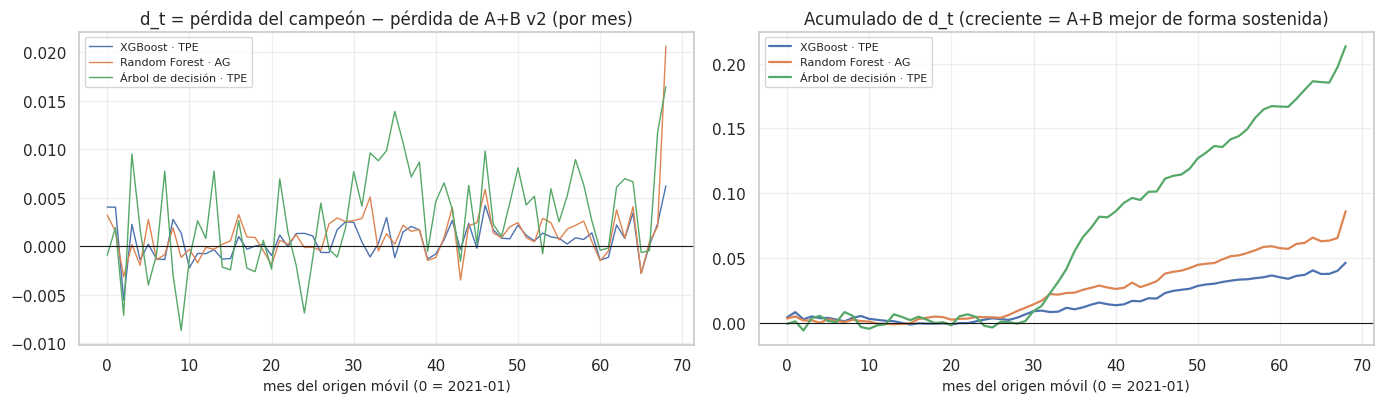

,XGBoost · TPE,Random Forest · AG,Árbol de decisión · TPE,KNN · TPE,Lasso · Grid,Ridge · Grid,SVR · AG
mean,0.00067,0.00125,0.00310,0.00556,0.01365,0.01365,0.01959
std,0.00184,0.00303,0.00508,0.00745,0.00709,0.00709,0.00575
min,-0.00554,-0.00348,-0.00869,-0.01051,0.00318,0.00318,0.00364
max,0.00624,0.02066,0.01648,0.04329,0.03836,0.03840,0.03476


In [15]:
# Diferencias de pérdida mes a mes frente a los campeones
D_MES = pd.DataFrame({"mes": datos.fecha_de_mes(np.unique(tmr)).strftime("%Y-%m")})
for n in DM.rival:
    _, Ln = ev.perdida_mensual(yr, pred[n], tmr); D_MES[n] = Ln - L_ab
eda.guardar_tabla(D_MES, "e2_stats_diferencias_mensuales.csv")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
for n in DM.rival[:3]:
    axs[0].plot(range(len(D_MES)), D_MES[n], lw=1, label=n); axs[1].plot(range(len(D_MES)), D_MES[n].cumsum(), lw=1.6, label=n)
axs[0].axhline(0, color="k", lw=0.8); axs[1].axhline(0, color="k", lw=0.8)
axs[0].set_title("d_t = pérdida del campeón − pérdida de A+B v2 (por mes)"); axs[1].set_title("Acumulado de d_t (creciente = A+B mejor de forma sostenida)")
for ax in axs:
    ax.set_xlabel("mes del origen móvil (0 = 2021-01)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); eda.guardar_figura(fig, "e2_stats_diferencias_mensuales.png"); plt.show()
D_MES.describe().loc[["mean", "std", "min", "max"]].round(5)

**Verificación de Ridge y Lasso.** Sus resultados casi idénticos (RMSLE y d de Cohen iguales a cuatro
decimales) no son una duplicación: son dos modelos distintos, con hiperparámetros distintos, cuyos pronósticos
difieren, pero ambos quedaron con una penalización tan pequeña que se comportan como la misma regresión lineal
sin penalizar.

In [16]:
# Ridge frente a Lasso: hiperparámetros y pronósticos
import json as _json
hp_r = _json.load(open(r2.OM / "hp_bench" / "Ridge__Grid.json"))["params"]; hp_l = _json.load(open(r2.OM / "hp_bench" / "Lasso__Grid.json"))["params"]
pr_, pl_ = O["Ridge · Grid"], O["Lasso · Grid"]
pd.DataFrame([{"Ridge · Grid α": hp_r["alpha"], "Lasso · Grid α": hp_l["alpha"], "predicciones idénticas": bool(np.array_equal(pr_, pl_)),
               "diferencia máxima (sismos)": float(np.abs(pr_ - pl_).max()), "correlación": float(np.corrcoef(pr_, pl_)[0, 1]),
               "RMSLE Ridge": ev.rmsle(yr, pr_), "RMSLE Lasso": ev.rmsle(yr, pl_)}]).T.rename(columns={0: "valor"})

,valor
Ridge · Grid α,0.001
Lasso · Grid α,0.00001
predicciones idénticas,False
diferencia máxima (sismos),0.020967
correlación,1.0
RMSLE Ridge,0.346347
RMSLE Lasso,0.346347


### 21.7 Control de *data snooping*: SPA de Hansen y Reality Check de White

Cuando se comparan varias versiones de un modelo contra un rival y se reporta la mejor, su p-valor individual es
optimista. El **SPA de Hansen (2005)** responde: *¿alguna de las versiones supera de verdad al rival, una vez se
cuenta que se compararon todas?* Aquí las versiones son el modelo propuesto y las de su ablación (sin B, sin B
ni núcleo ZINB y sin la calibración final). Se usa el bootstrap estacionario de bloques de meses (2 000
réplicas) y se reportan el p consistente de Hansen y el del **Reality Check de White (2000)** (más conservador).

- **(i) Cada campeón como benchmark** frente a todas esas versiones. H0: ninguna supera al campeón. Se hace
  para los 7 campeones y se ajusta por Holm (7).
- **(ii) Al revés:** benchmark = A+B v2; alternativas = los 7 campeones. H0: ningún campeón supera a A+B v2.

In [17]:
# SPA y Reality Check: control de data snooping entre las variantes del modelo propuesto
VAR = r2.variantes_propuestas()
assert np.allclose(VAR["A+B v2 (final)"], O["A+B v2"])
Lv = np.column_stack([ev.perdida_mensual(yr, p, tmr)[1] for p in VAR.values()])
filas = []
for n in CAMP7:
    _, Lb = ev.perdida_mensual(yr, pred[n], tmr)
    s_ = est.spa(Lb, Lv, B=2000)
    filas.append({"benchmark": n, "versiones comparadas": len(VAR), "estadístico": s_["estadistico"], "p SPA (consistente)": s_["p_consistente"],
                  "p Reality Check": s_["p_superior"]})
SPA = pd.DataFrame(filas)
SPA["p SPA Holm (7)"] = eda.holm(SPA["p SPA (consistente)"].values); SPA["p RC Holm (7)"] = eda.holm(SPA["p Reality Check"].values)
L7 = np.column_stack([ev.perdida_mensual(yr, pred[n], tmr)[1] for n in CAMP7])
s2 = est.spa(L_ab, L7, B=2000)
eda.guardar_tabla(SPA, "e2_stats_spa.csv")
pd.DataFrame({"versión": list(VAR), "RMSLE": [ev.rmsle(yr, p) for p in VAR.values()]}).round(4)

,versión,RMSLE
0,A+B v2 (final),0.3260
1,Sin calibración final,0.3263
2,Sin B,0.3267
3,Sin B ni núcleo ZINB,0.3267


In [18]:
SPA.round(4)

,benchmark,versiones comparadas,estadístico,p SPA (consistente),p Reality Check,p SPA Holm (7),p RC Holm (7)
0,Random Forest · AG,4,3.9091,0.0005,0.0005,0.0015,0.0015
1,XGBoost · TPE,4,3.2964,0.0045,0.0045,0.0045,0.0045
2,KNN · TPE,4,6.1538,0.0000,0.0000,0.0000,0.0000
3,SVR · AG,4,26.7042,0.0000,0.0000,0.0000,0.0000
4,Árbol de decisión · TPE,4,4.0017,0.0005,0.0005,0.0015,0.0015
5,Ridge · Grid,4,17.2474,0.0000,0.0000,0.0000,0.0000
6,Lasso · Grid,4,17.2640,0.0000,0.0000,0.0000,0.0000


In [19]:
md(f"- **(i)** Con las {len(VAR)} versiones a la vez, el p del SPA tras Holm es como máximo {p_fmt(SPA['p SPA Holm (7)'].max())} y el del "
   f"Reality Check {p_fmt(SPA['p RC Holm (7)'].max())}. "
   + ("**La superioridad sobre cada campeón se mantiene aun contando todas las versiones a la vez.**" if (SPA['p RC Holm (7)'] < 0.05).all() else
      f"Se mantiene frente a {int((SPA['p RC Holm (7)'] < 0.05).sum())} de 7 campeones con el Reality Check.") + "\n"
   f"- **(ii)** p consistente = {p_fmt(s2['p_consistente'])}: "
   + ("ningún campeón tradicional supera a A+B v2." if s2["p_consistente"] >= 0.05 else "algún campeón supera a A+B v2."))
s1 = {"p_consistente": SPA["p SPA Holm (7)"].max()}
bench_ext = CAMP_R.iloc[0]

- **(i)** Con las 4 versiones a la vez, el p del SPA tras Holm es como máximo 0,004 y el del Reality Check 0,004. **La superioridad sobre cada campeón se mantiene aun contando todas las versiones a la vez.**
- **(ii)** p consistente = 1,000: ningún campeón tradicional supera a A+B v2.

## 21.8 Independencia de los residuos

Las pruebas anteriores suponen algo sobre la dependencia de los errores: DM y GW usan una varianza robusta a
autocorrelación (Newey-West), y el MCS y el SPA remuestrean bloques de meses. Para saber si esas precauciones son
necesarias, y si los residuos de los modelos dejan estructura sin explicar, se aplican cuatro pruebas a los
residuos de prueba r = log1p(ŷ) − log1p(y) de A+B v2 y del campeón de cada uno de los 7 modelos en el origen
móvil 2021–2026:

| Prueba | Qué detecta | Sobre qué serie |
|---|---|---|
| Escanciano-Lobato (2009) | autocorrelación, con número de rezagos automático y robusta a heterocedasticidad | residuo medio mensual (69 meses) y serie de cada celda |
| Breusch-Godfrey (12 rezagos) | autocorrelación lineal hasta un año | residuo medio mensual |
| BDS (dimensiones 2 y 3) | dependencia no lineal | residuo medio mensual |
| I de Moran (8 vecinos, 499 permutaciones) | dependencia espacial entre celdas | residuos de cada mes |

Se calculan con `scripts/independencia_residuos.py` (resultados en `resultados/e2/independencia_*.csv`).

In [20]:
# Pruebas de independencia de residuos (Escanciano-Lobato, Breusch-Godfrey, BDS, Moran)
IR = pd.read_csv(cfg.RESULTADOS / "e2" / "independencia_residuos.csv")
IC = pd.read_csv(cfg.RESULTADOS / "e2" / "independencia_celdas.csv")
IM = pd.read_csv(cfg.RESULTADOS / "e2" / "independencia_moran.csv")
ID = pd.read_csv(cfg.RESULTADOS / "e2" / "independencia_diferencias.csv")
MOR = IM.groupby("modelo").agg(I_mediana=("I", "median"), meses_p05=("p", lambda v: (v < 0.05).mean())).reset_index()
IND = IR[["modelo", "RMSLE", "EL_p", "BG_p", "BDS_p_dim2", "BDS_p_dim3"]].merge(
    IC[["modelo", "frac_p<0.05", "frac_p<0.05_Holm"]], on="modelo").merge(MOR, on="modelo")
IND.columns = ["modelo", "RMSLE", "p Escanciano-Lobato", "p Breusch-Godfrey", "p BDS m=2", "p BDS m=3",
               "celdas con autocorrelación (p<0,05)", "celdas con autocorrelación (Holm)", "I de Moran mediano", "meses con Moran p<0,05"]
eda.guardar_tabla(IND, "e2_stats_independencia.csv")
IND.round(3)

,modelo,RMSLE,p Escanciano-Lobato,p Breusch-Godfrey,p BDS m=2,p BDS m=3,"celdas con autocorrelación (p<0,05)",celdas con autocorrelación (Holm),I de Moran mediano,"meses con Moran p<0,05"
0,A+B (propuesto),0.326,0.183,0.453,0.380,0.835,0.286,0.170,-0.001,0.101
1,Random Forest (Genético (DEAP)),0.328,0.503,0.409,0.016,0.203,0.291,0.181,0.006,0.101
2,XGBoost (Bayesiano (TPE)),0.327,0.621,0.460,0.024,0.248,0.308,0.203,0.006,0.101
3,KNN (Bayesiano (TPE)),0.334,0.467,0.467,0.240,0.337,0.214,0.033,0.003,0.101
4,SVR (Genético (DEAP)),0.355,0.579,0.302,0.510,0.566,0.258,0.159,0.065,0.478
5,Árbol de decisión (Bayesiano (TPE)),0.331,0.418,0.447,0.005,0.084,0.264,0.143,0.003,0.087
6,Ridge (Grid),0.346,0.500,0.528,0.011,0.062,0.280,0.154,-0.001,0.116
7,Lasso (Grid),0.346,0.501,0.528,0.013,0.068,0.280,0.154,-0.001,0.116


In [21]:
# Lectura de las pruebas de independencia
ab_i = IND.iloc[0]
md(f"- **Serie mensual, autocorrelación lineal.** Ninguna de las dos pruebas rechaza la independencia en ningún modelo "
   f"(Escanciano-Lobato p ≥ {IND['p Escanciano-Lobato'].min():.2f}; Breusch-Godfrey p ≥ {IND['p Breusch-Godfrey'].min():.2f}). "
   f"El error agregado de un mes no anticipa el del mes siguiente: los modelos no dejan un patrón temporal lineal sin aprovechar.\n"
   f"- **Dependencia no lineal (BDS).** En dimensión 2 se rechaza en {int((IND['p BDS m=2'] < 0.05).sum())} de {len(IND)} modelos "
   f"(A+B v2: p = {ab_i['p BDS m=2']:.3f}). Es una dependencia débil de tipo no lineal, compatible con meses de enjambres que elevan el "
   f"error de todos los modelos a la vez, y no aparece en las pruebas lineales.\n"
   f"- **Dentro de cada celda.** Entre {100 * IND['celdas con autocorrelación (Holm)'].min():.0f} % y "
   f"{100 * IND['celdas con autocorrelación (Holm)'].max():.0f} % de las celdas conservan autocorrelación tras Holm (A+B v2: "
   f"{100 * ab_i['celdas con autocorrelación (Holm)']:.0f} %). Son celdas con secuencias de réplicas largas, donde el error de un mes se "
   f"repite al siguiente.\n"
   f"- **Espacial.** El I de Moran mediano es casi cero (A+B v2: {ab_i['I de Moran mediano']:.3f}) y solo "
   f"{100 * ab_i['meses con Moran p<0,05']:.0f} % de los meses es significativo en A+B v2, cerca del 5 % esperado por azar; la excepción es "
   f"SVR ({100 * IND.set_index('modelo').filter(like='SVR', axis=0)['meses con Moran p<0,05'].iloc[0]:.0f} % de los meses), cuyos errores "
   f"quedan agrupados en el espacio.\n"
   f"- **Diferencias de pérdida (base de Diebold-Mariano).** Escanciano-Lobato detecta autocorrelación (p < 0,05) en la serie A+B v2 − rival "
   f"en {int((ID['EL_p'] < 0.05).sum())} de {len(ID)} comparaciones"
   + (f" ({', '.join(ID.loc[ID.EL_p < 0.05, 'rival'])}; p = {ID.EL_p.min():.3f})" if (ID['EL_p'] < 0.05).any() else "")
   + "; Breusch-Godfrey no la detecta en ninguna"
   + (" " if (ID['BG_p'] >= 0.05).all() else " (salvo alguna) ") + "y la varianza de Newey-West de la prueba DM cubre ese caso.\n\n"
   f"**Consecuencia para las pruebas.** Los residuos agregados por mes se comportan como independientes, así que usar el **mes** como "
   f"unidad de comparación es adecuado. La dependencia que sí existe (dentro de algunas celdas, no lineal y entre filas del mismo mes) "
   f"justifica las precauciones ya tomadas: varianza Newey-West en DM y GW, bootstrap por bloques en MCS y SPA, y no tratar las 11 754 "
   f"filas como observaciones independientes.")

- **Serie mensual, autocorrelación lineal.** Ninguna de las dos pruebas rechaza la independencia en ningún modelo (Escanciano-Lobato p ≥ 0.18; Breusch-Godfrey p ≥ 0.30). El error agregado de un mes no anticipa el del mes siguiente: los modelos no dejan un patrón temporal lineal sin aprovechar.
- **Dependencia no lineal (BDS).** En dimensión 2 se rechaza en 5 de 8 modelos (A+B v2: p = 0.380). Es una dependencia débil de tipo no lineal, compatible con meses de enjambres que elevan el error de todos los modelos a la vez, y no aparece en las pruebas lineales.
- **Dentro de cada celda.** Entre 3 % y 20 % de las celdas conservan autocorrelación tras Holm (A+B v2: 17 %). Son celdas con secuencias de réplicas largas, donde el error de un mes se repite al siguiente.
- **Espacial.** El I de Moran mediano es casi cero (A+B v2: -0.001) y solo 10 % de los meses es significativo en A+B v2, cerca del 5 % esperado por azar; la excepción es SVR (48 % de los meses), cuyos errores quedan agrupados en el espacio.
- **Diferencias de pérdida (base de Diebold-Mariano).** Escanciano-Lobato detecta autocorrelación (p < 0,05) en la serie A+B v2 − rival en 1 de 7 comparaciones (Árbol de decisión (Bayesiano (TPE)); p = 0.019); Breusch-Godfrey no la detecta en ninguna y la varianza de Newey-West de la prueba DM cubre ese caso.

**Consecuencia para las pruebas.** Los residuos agregados por mes se comportan como independientes, así que usar el **mes** como unidad de comparación es adecuado. La dependencia que sí existe (dentro de algunas celdas, no lineal y entre filas del mismo mes) justifica las precauciones ya tomadas: varianza Newey-West en DM y GW, bootstrap por bloques en MCS y SPA, y no tratar las 11 754 filas como observaciones independientes.

## 21.9 Resumen de la evidencia

In [22]:
# Resumen de todas las pruebas estadísticas
filas = [("Clasificación", "Friedman (7 campeones × 69 meses)", f"p = {p_fmt(fb['p'])}", "hay diferencias entre familias" if fb["p"] < 0.05 else "sin diferencias"),
         ("Clasificación", "Nemenyi / CD", f"CD = {cd7:.2f}; mejor rango: {nombres7[orden[0]]}", "ver diagrama"),
         ("Clasificación", f"DeLong + Holm ({len(DL)} pares)", f"{int((DL['p Holm'] < 0.05).sum())} de {len(DL)} significativos", "δ de Cliff " + ", ".join(sorted(set(DL['magnitud δ'])))),
         ("Regresión", "MCS 90 % (origen móvil, 7 campeones + A+B v2 + 2 líneas base)", f"{len(fin)} en el conjunto", ", ".join(fin)),
         ("Regresión", "Giacomini-White + Holm (7 campeones)", f"{int((GC['p GW Holm'] < 0.05).sum())} de 7 significativos", "habilidad condicional"),
         ("Regresión", "Clark-West + Holm (7 campeones, anidados)", f"{int((GC['p CW Holm'] < 0.05).sum())} de 7 significativos", "corrige el anidamiento"),
         ("Regresión", "Familia DM + GW + CW (21 contrastes, Holm)", f"las tres significativas frente a {int(TAB_FAM['las tres significativas'].sum())} de 7", f"mayor p ajustado {p_fmt(FAM['p Holm (21)'].max())}"),
         ("Regresión", "DM-HLN + Holm (7 campeones)", f"mejor que {int((DM.veredicto == 'A+B v2 mejor').sum())} de 7", f"d de Cohen frente al más cercano: {DM['d de Cohen'].iloc[0]:.2f}"),
         ("Regresión", f"SPA y Reality Check ({len(VAR)} versiones del modelo propuesto vs cada campeón, Holm)", f"p máx. SPA {p_fmt(SPA['p SPA Holm (7)'].max())}; RC {p_fmt(SPA['p RC Holm (7)'].max())}", "controla el data snooping"),
         ("Regresión", "Independencia de residuos (EL, BG, BDS, Moran)", f"serie mensual sin autocorrelación en {int(((IND['p Escanciano-Lobato'] >= 0.05) & (IND['p Breusch-Godfrey'] >= 0.05)).sum())} de {len(IND)} modelos", "valida el mes como unidad de comparación")]
RES = pd.DataFrame(filas, columns=["tarea", "prueba", "resultado", "comentario"])
eda.guardar_tabla(RES, "e2_stats_resumen.csv")
RES

,tarea,prueba,resultado,comentario
0,Clasificación,Friedman (7 campeones × 69 meses),"p = < 0,001",hay diferencias entre familias
1,Clasificación,Nemenyi / CD,CD = 1.08; mejor rango: XGBoost,ver diagrama
2,Clasificación,DeLong + Holm (3 pares),3 de 3 significativos,"δ de Cliff despreciable, pequeño"
3,Regresión,"MCS 90 % (origen móvil, 7 campeones + A+B v2 +...",1 en el conjunto,A+B v2 (propuesto)
4,Regresión,Giacomini-White + Holm (7 campeones),7 de 7 significativos,habilidad condicional
5,Regresión,"Clark-West + Holm (7 campeones, anidados)",7 de 7 significativos,corrige el anidamiento
6,Regresión,"Familia DM + GW + CW (21 contrastes, Holm)",las tres significativas frente a 7 de 7,"mayor p ajustado 0,006"
7,Regresión,DM-HLN + Holm (7 campeones),mejor que 7 de 7,d de Cohen frente al más cercano: 0.36
8,Regresión,SPA y Reality Check (4 versiones del modelo pr...,"p máx. SPA 0,004; RC 0,004",controla el data snooping
9,Regresión,"Independencia de residuos (EL, BG, BDS, Moran)",serie mensual sin autocorrelación en 8 de 8 mo...,valida el mes como unidad de comparación


In [23]:
md(f"**Interpretación de los p-valores en contexto.** Un p-valor pequeño en DM no dice que un modelo sea «mucho» mejor: dice que, si "
   f"los dos tuvieran la misma capacidad predictiva, sería improbable observar una ventaja tan sistemática mes a mes. A+B v2 tiene la menor "
   f"pérdida media del origen móvil, pero frente al campeón más cercano ({DM.rival.iloc[0]}) la diferencia es de "
   f"≈ {100 * (DM['RMSLE rival'].iloc[0] - ev.rmsle(yr, O['A+B v2'])) / DM['RMSLE rival'].iloc[0]:.2f} % de RMSLE"
   + (", y tras Holm **no** es significativa frente a " + ", ".join(DM.loc[DM.veredicto == 'sin diferencia', 'rival']) + ". "
      "La conclusión prudente es que A+B v2 está **en el grupo de los mejores** y es significativamente mejor que el resto."
      if (DM.veredicto == 'sin diferencia').any() else ", pequeña pero significativa frente a todos los campeones tras Holm.")
   + " El MCS, que controla todas las comparaciones a la vez, es la referencia para decidir quién está en ese grupo.")

**Interpretación de los p-valores en contexto.** Un p-valor pequeño en DM no dice que un modelo sea «mucho» mejor: dice que, si los dos tuvieran la misma capacidad predictiva, sería improbable observar una ventaja tan sistemática mes a mes. A+B v2 tiene la menor pérdida media del origen móvil, pero frente al campeón más cercano (XGBoost · TPE) la diferencia es de ≈ 0.32 % de RMSLE, pequeña pero significativa frente a todos los campeones tras Holm. El MCS, que controla todas las comparaciones a la vez, es la referencia para decidir quién está en ese grupo.